In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

df = pd.read_csv("CAR DETAILS FROM CAR DEKHO.csv")

print(df.head())
print("Dataset Shape:", df.shape)
df.info()

print("\nSummary Statistics:")
print(df.describe(include='all'))

                       name  year  selling_price  km_driven    fuel  \
0             Maruti 800 AC  2007          60000      70000  Petrol   
1  Maruti Wagon R LXI Minor  2007         135000      50000  Petrol   
2      Hyundai Verna 1.6 SX  2012         600000     100000  Diesel   
3    Datsun RediGO T Option  2017         250000      46000  Petrol   
4     Honda Amaze VX i-DTEC  2014         450000     141000  Diesel   

  seller_type transmission         owner  
0  Individual       Manual   First Owner  
1  Individual       Manual   First Owner  
2  Individual       Manual   First Owner  
3  Individual       Manual   First Owner  
4  Individual       Manual  Second Owner  
Dataset Shape: (4340, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling

Description: The Car Dekho dataset contains car details such as manufacturing year, selling price, kilometres driven, fuel and transmission type.
- Input (X): Car details.
- Target (y): Transmission.
- Manual = 0
- Automatic = 1

Dataset Source: Kaggle – Vehicle Dataset from Car Dekho.

https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho

In [47]:
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)
print("\nClass Distribution:")
print(df['transmission'].value_counts())


print("\nTransmission Labels:")
print(df['transmission'].unique())

Missing Values:
 name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64
Duplicate Records: 763
Shape after cleaning: (3577, 8)

Class Distribution:
transmission
Manual       3265
Automatic     312
Name: count, dtype: int64

Transmission Labels:
['Manual' 'Automatic']


Missing values and duplicate records are checked. Duplicate records are removed to avoid repeated observations.

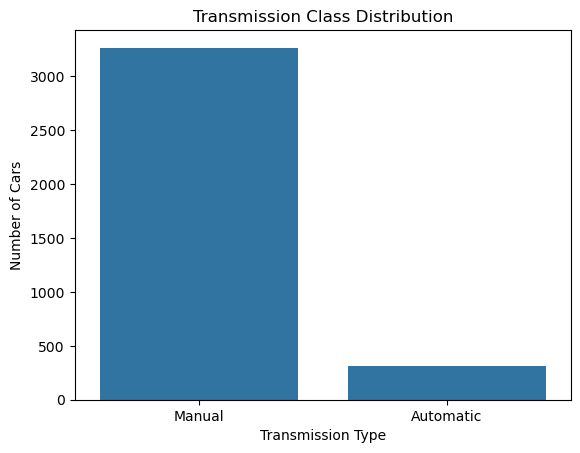

In [48]:
sns.countplot(data=df, x='transmission')

plt.title("Transmission Class Distribution")
plt.xlabel("Transmission Type")
plt.ylabel("Number of Cars")
plt.show()

Manual cars are more common than automatic cars. Therefore, the dataset has an imbalanced class distribution.

In [49]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

X = df[['year', 'selling_price', 'km_driven',
        'fuel', 'seller_type', 'owner']]

y = df['transmission'].map({'Manual': 0, 'Automatic': 1})

numeric_features = ['year', 'selling_price', 'km_driven']
categorical_features = ['fuel', 'seller_type', 'owner']

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

Description:
- One-Hot Encoding converts categorical data into numerical form.
- StandardScaler scales numerical features.
- The name column is excluded because it is not needed for this model.

In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Class Counts:")
print(y_train.value_counts())

print("\nTesting Class Counts:")
print(y_test.value_counts())

Training Records: 2861
Testing Records: 716

Training Class Counts:
transmission
0    2611
1     250
Name: count, dtype: int64

Testing Class Counts:
transmission
0    654
1     62
Name: count, dtype: int64


The dataset is divided into 80% training data and 20% testing data. Stratified splitting maintains the class proportions in both sets.

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model trained successfully!")

feature_names = model.named_steps['preprocessing'].get_feature_names_out()
coefficients = model.named_steps['classifier'].coef_[0]

coef_table = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

print("Intercept:", model.named_steps['classifier'].intercept_)
print("\nCoefficients:")
print(coef_table)

Model trained successfully!
Intercept: [-2.73513668]

Coefficients:
                              Feature  Coefficient
0                           num__year    -0.312584
1                  num__selling_price     1.927844
2                      num__km_driven    -0.038119
3                       cat__fuel_CNG    -0.577983
4                    cat__fuel_Diesel    -0.650490
5                  cat__fuel_Electric     0.889021
6                       cat__fuel_LPG    -0.343851
7                    cat__fuel_Petrol     0.644664
8             cat__seller_type_Dealer     0.456746
9         cat__seller_type_Individual    -0.468809
10  cat__seller_type_Trustmark Dealer    -0.026577
11             cat__owner_First Owner    -0.029494
12    cat__owner_Fourth & Above Owner     0.155141
13            cat__owner_Second Owner     0.319963
14          cat__owner_Test Drive Car    -1.127542
15             cat__owner_Third Owner     0.643293


Logistic Regression is trained using the training dataset. It predicts the probability of a car having automatic transmission.

Why not Linear Regression? Linear Regression can produce values outside 0 and 1, whereas Logistic Regression uses the sigmoid function to produce probabilities between 0 and 1.

In [52]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Probability': y_prob,
    'Predicted': y_pred
})

print(results.head(10))

   Actual  Probability  Predicted
0       0     0.033060          0
1       0     0.035451          0
2       0     0.044066          0
3       0     0.019199          0
4       0     0.072842          0
5       0     0.050880          0
6       0     0.173118          0
7       1     0.110401          0
8       0     0.029527          0
9       0     0.018497          0


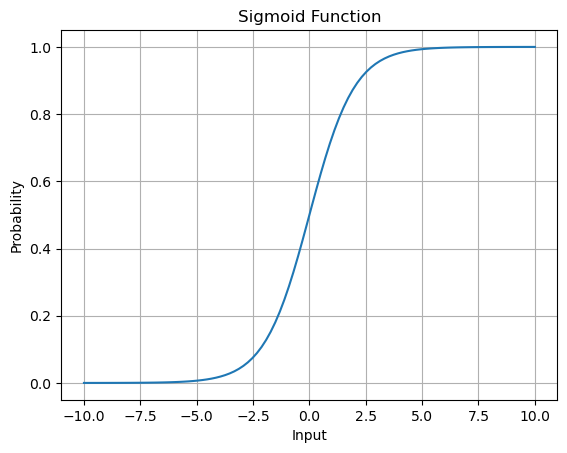

In [53]:
z = np.linspace(-10, 10, 100)
sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.grid()
plt.show()

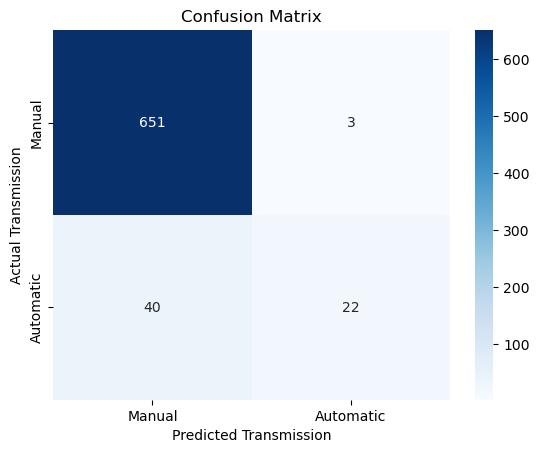

True Negative: 651
False Positive: 3
False Negative: 40
True Positive: 22


In [54]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Manual', 'Automatic'],
    yticklabels=['Manual', 'Automatic']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Transmission")
plt.ylabel("Actual Transmission")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

In [64]:
train_pred = model.predict(X_train)

print("Training Metrics")
print("Accuracy:", accuracy_score(y_train, train_pred))
print("Precision:", precision_score(y_train, train_pred, zero_division=0))
print("Recall:", recall_score(y_train, train_pred, zero_division=0))
print("F1 Score:", f1_score(y_train, train_pred, zero_division=0))

print("\nTesting Metrics")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

Training Metrics
Accuracy: 0.9328905976931143
Precision: 0.79
Recall: 0.316
F1 Score: 0.4514285714285714

Testing Metrics
Accuracy: 0.9399441340782123
Precision: 0.88
Recall: 0.3548387096774194
F1 Score: 0.5057471264367817


In [56]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

base_pred = baseline.predict(X_test)

print("Baseline Accuracy:",
      accuracy_score(y_test, base_pred))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

Baseline Accuracy: 0.9134078212290503
Logistic Regression Accuracy: 0.9399441340782123


The baseline always predicts the majority class. We compare its accuracy with Logistic Regression to check whether our model provides improvement.

In [ ]:
threshold_results = []

for t in [0.3, 0.5, 0.7]:
    pred = (y_prob >= t).astype(int)

    threshold_results.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred, zero_division=0),
        'F1 Score': f1_score(y_test, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df)


Threshold: 0.3
Predicted Automatic Cars: 36
Accuracy: 0.9301675977653632
Precision: 0.6666666666666666
Recall: 0.3870967741935484
F1 Score: 0.4897959183673469

Threshold: 0.5
Predicted Automatic Cars: 25
Accuracy: 0.9399441340782123
Precision: 0.88
Recall: 0.3548387096774194
F1 Score: 0.5057471264367817

Threshold: 0.7
Predicted Automatic Cars: 18
Accuracy: 0.9385474860335196
Precision: 1.0
Recall: 0.2903225806451613
F1 Score: 0.45


We compare thresholds 0.3, 0.5 and 0.7. A lower threshold generally increases recall, while a higher threshold generally increases precision.

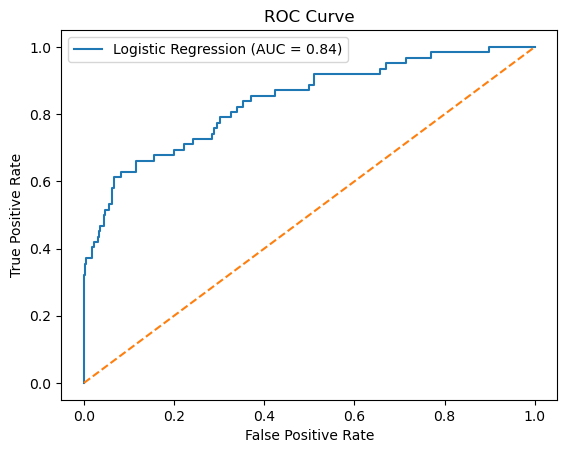

ROC-AUC Score: 0.8384877182598401


In [58]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], '--')

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("ROC-AUC Score:", roc_auc)

The ROC curve shows how well the model separates manual and automatic cars at different thresholds.

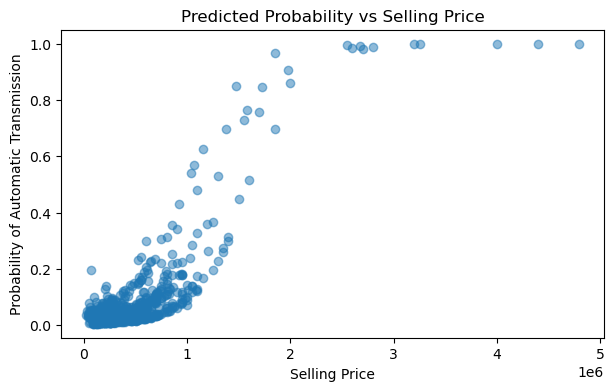

In [59]:
plt.figure(figsize=(7, 4))

plt.scatter(X_test['selling_price'], y_prob, alpha=0.5)

plt.title("Predicted Probability vs Selling Price")
plt.xlabel("Selling Price")
plt.ylabel("Probability of Automatic Transmission")
plt.show()

In [60]:
new_car = pd.DataFrame({
    'year': [2018],
    'selling_price': [500000],
    'km_driven': [30000],
    'fuel': ['Petrol'],
    'seller_type': ['Individual'],
    'owner': ['First Owner']
})

prob = model.predict_proba(new_car)[0][1]

print("Automatic Probability:", prob)
print("Predicted Class:",
      "Automatic" if prob >= 0.5 else "Manual")

Automatic Probability: 0.055532368936524766
Predicted Class: Manual


In [61]:
train_pred = model.predict(X_train)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, y_pred))

Training Accuracy: 0.9328905976931143
Testing Accuracy: 0.9399441340782123


In [66]:
decision_log = [
    "Positive class: Automatic (1), Negative class: Manual (0).",
    "The dataset is imbalanced, so accuracy alone is not enough.",
    "F1-score balances precision and recall.",
    "Threshold 0.5 gives the highest F1-score among the tested thresholds.",
    "There are 40 false negatives and 3 false positives.",
    "Threshold 0.3 can be considered if higher recall is important.",
    "The model prediction is an estimate, not a guaranteed result."
]

for decision in decision_log:
    print(decision)

Positive class: Automatic (1), Negative class: Manual (0).
The dataset is imbalanced, so accuracy alone is not enough.
F1-score balances precision and recall.
Threshold 0.5 gives the highest F1-score among the tested thresholds.
There are 40 false negatives and 3 false positives.
Threshold 0.3 can be considered if higher recall is important.
The model prediction is an estimate, not a guaranteed result.


Logistic Regression was used to classify cars into Manual and Automatic transmission categories.

The model achieved 93.99% testing accuracy and an ROC-AUC score of approximately 0.84. It performed better than the majority-class baseline.

The 0.5 threshold gave the highest F1-score among the tested thresholds.

Limitations:
- The dataset contains more Manual cars than Automatic cars.
- The model has low recall for Automatic cars.
- Predictions depend on the selected features and dataset quality.
- Predictions are estimates and are not guaranteed to be correct.